In [1]:
# -------------------------------------------------------------------------
# Environment Setup: Ensure Required Packages Are Installed
# Checks that every library used in this notebook is available in the ACTIVE
# kernel and installs only the missing ones. This makes "Run All" work no matter
# which Python environment / .venv the kernel was started from.
# -------------------------------------------------------------------------
import importlib
import importlib.util
import subprocess
import sys

# import name -> pip package name
required_packages = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}

missing_packages = [pip_name for module, pip_name in required_packages.items()
                    if importlib.util.find_spec(module) is None]

if missing_packages:
    print(f"Installing missing packages into {sys.executable}: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

All required packages are already installed.


# Model Training & Evaluation: Gaussian Naïve Bayes

**Team Member:** Mustafa

This notebook trains the probabilistic baseline model (Gaussian Naïve Bayes) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model on the holdout **Test partition ($N = 4,000$, 20%)** following an **80/20 train/test split**.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

In [2]:
# Import necessary libraries for data manipulation and mathematical operations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import the Gaussian Naïve Bayes algorithm and evaluation metrics from scikit-learn
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configure visual aesthetics for professional graphing
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 1. Data Loading
We load the partitioned 80/20 subsets from the `Data/` directory. We use `X_train` / `y_train` ($N = 16,000$) for model fitting, and `X_test` / `y_test` ($N = 4,000$) for out-of-sample evaluation.

In [3]:
# -------------------------------------------------------------------------
# Load Processed Training and Testing Sets (80/20 Partition)
# -------------------------------------------------------------------------
from pathlib import Path
data_dir = Path.cwd() / "Data"
if not data_dir.exists():
    data_dir = (Path.cwd() / ".." / "Data").resolve()
base_path = f"{data_dir.as_posix()}/"

# Load the predictor features (X) for the training subset (80%)
X_train = pd.read_csv(f"{base_path}processed_X_train.csv")

# Load the target variable (y) for the training subset, isolating just the label column
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

# Load the predictor features (X) for the testing subset (20%)
X_test = pd.read_csv(f"{base_path}processed_X_test.csv")

# Load the target variable (y) for the testing subset, isolating just the label column
y_test = pd.read_csv(f"{base_path}processed_y_test.csv")['Layoff_Risk']

# Print the dimensionality to verify successful loading
print(f"Training set (80%): {X_train.shape[0]:,} rows x {X_train.shape[1]} columns")
print(f"Testing set  (20%): {X_test.shape[0]:,} rows x {X_test.shape[1]} columns")

Training set (80%): 16,000 rows x 11 columns
Testing set  (20%): 4,000 rows x 11 columns


In [4]:
# -------------------------------------------------------------------------
# Dataset Verification: Feature Set & Class Balance
# Confirms that the newly engineered 5-feature pipeline (11 predictors after
# one-hot encoding) was loaded correctly and establishes the majority-class baseline.
# -------------------------------------------------------------------------
print("--- PREDICTOR COLUMNS LOADED (X_train) ---")
for idx, col in enumerate(X_train.columns, start=1):
    print(f"{idx:>2}. {col}")
print(f"\nTotal predictors: {X_train.shape[1]}")

# Confirm train and test partitions share an identical schema
assert list(X_train.columns) == list(X_test.columns), "Schema mismatch between train and test sets!"
print("Schema check passed: train and test columns are identical.")

# Verify there are no missing values that would break model fitting
print(f"Missing values in X_train: {int(X_train.isnull().sum().sum())} | X_test: {int(X_test.isnull().sum().sum())}")

# Class distribution and majority-class baseline accuracy
class_label_map = {0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'}
class_dist = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test Count': y_test.value_counts().sort_index(),
    'Test (%)': (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index=class_label_map)
print("\n--- CLASS DISTRIBUTION ---")
display(class_dist)

# A model that always predicts the most frequent training class sets the floor any real model must beat
majority_class = y_train.value_counts().idxmax()
baseline_acc = (y_test == majority_class).mean()
print(f"Majority-class baseline accuracy on holdout test set: {baseline_acc:.4f}")

--- PREDICTOR COLUMNS LOADED (X_train) ---
 1. Years_of_Experience
 2. Routine_Task_Percentage
 3. Tasks_Automated_Percentage
 4. Number_of_AI_Tools_Used
 5. Industry_Education
 6. Industry_Finance
 7. Industry_Healthcare
 8. Industry_Logistics
 9. Industry_Manufacturing
10. Industry_Retail
11. Industry_Telecom

Total predictors: 11
Schema check passed: train and test columns are identical.
Missing values in X_train: 0 | X_test: 0

--- CLASS DISTRIBUTION ---


,Train Count,Train (%),Test Count,Test (%)
Layoff_Risk,,,,
Low (0),5282,33.01,1320,33.0
Medium (1),5281,33.01,1320,33.0
High (2),5437,33.98,1360,34.0


Majority-class baseline accuracy on holdout test set: 0.3400


> **Methodological Rule — Zero-Leakage Training:**
> The model is exposed solely to the 16,000 training records ($N = 16,000$). Evaluation is conducted against the 4,000 holdout test records ($N = 4,000$). The test partition remained strictly unvisited during prior distribution estimation.

## 2. Model Initialization and Training

Gaussian Naïve Bayes models each predictor within each class as a normal distribution and combines them under the assumption of **conditional independence**. Two properties of our feature set are worth noting up front: (1) `Routine_Task_Percentage` and `Tasks_Automated_Percentage` are strongly correlated ($r = 0.89$), which violates the independence assumption, and (2) the 7 `Industry_*` one-hot indicators are binary rather than Gaussian. Both can limit the model, so this notebook serves as a probabilistic baseline against which Gradient Boosting is compared.

In [5]:
# -------------------------------------------------------------------------
# Fit Gaussian Naïve Bayes
# -------------------------------------------------------------------------
# Initialize the Gaussian Naïve Bayes model. 
# This model assumes features follow a normal distribution and are conditionally independent.
gnb = GaussianNB()

# Fit the model strictly to the training data. This calculates the prior probabilities 
# and class-conditional likelihoods for each feature based ONLY on X_train and y_train.
gnb.fit(X_train, y_train)

print("Gaussian Naïve Bayes training completed successfully!")

Gaussian Naïve Bayes training completed successfully!


In [6]:
# -------------------------------------------------------------------------
# Overfitting Check: Training vs. Testing Accuracy
# Naïve Bayes has low parameter capacity, so train and test accuracy align closely.
# -------------------------------------------------------------------------
train_acc = accuracy_score(y_train, gnb.predict(X_train))
test_acc = accuracy_score(y_test, gnb.predict(X_test))

print(f"Training Accuracy (80%): {train_acc:.4f}")
print(f"Testing Accuracy  (20%): {test_acc:.4f}")
print(f"Generalization Gap (Train - Test): {train_acc - test_acc:+.4f}")

# Learned class prior probabilities P(class), estimated from X_train/y_train only
print("\n--- LEARNED CLASS PRIORS ---")
display(pd.Series(gnb.class_prior_, index=['Low (0)', 'Medium (1)', 'High (2)'], name='Prior').round(4).to_frame())

Training Accuracy (80%): 0.7231
Testing Accuracy  (20%): 0.7335
Generalization Gap (Train - Test): -0.0104

--- LEARNED CLASS PRIORS ---


,Prior
Low (0),0.3301
Medium (1),0.3301
High (2),0.3398


## 3. Test Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [7]:
# -------------------------------------------------------------------------
# Predict on Holdout Test Set
# -------------------------------------------------------------------------
# Generate predicted class labels for the test subset
y_pred = gnb.predict(X_test)

# Calculate the overall proportion of correct predictions across all classes
acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {acc:.4f}\n")

# Generate a confusion matrix to evaluate class-level true positives, false positives, etc.
cm = confusion_matrix(y_test, y_pred)

# Define the categorical class labels for clean iteration and printing
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

# Iterate through each unique class to calculate One-vs-Rest metrics
for i, label in enumerate(classes):
    # True Positives: diagonal element for the current class
    tp = cm[i, i]
    
    # False Negatives: sum of actual class row minus true positives
    fn = cm[i, :].sum() - tp
    
    # False Positives: sum of predicted class column minus true positives
    fp = cm[:, i].sum() - tp
    
    # True Negatives: total observations minus (TP + FP + FN)
    tn = cm.sum() - (tp + fn + fp)
    
    # Calculate Sensitivity (Recall): True Positives / Actual Positives
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Calculate Specificity (True Negative Rate): True Negatives / Actual Negatives
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Append to lists so we can calculate macro averages later
    sensitivities.append(sens)
    specificities.append(spec)
    
    # Print the per-class results
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

# Calculate and print the unweighted macro averages across all three classes
print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Test Accuracy: 0.7335

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.8659
  - Specificity (TNR):    0.8616
Medium (1):
  - Sensitivity (Recall): 0.5311
  - Specificity (TNR):    0.8388
High (2):
  - Sensitivity (Recall): 0.8015
  - Specificity (TNR):    0.9004

--- Macro Averages ---
Macro Sensitivity: 0.7328
Macro Specificity: 0.8669


In [8]:
# -------------------------------------------------------------------------
# Consolidated Per-Class Metrics Table & scikit-learn Classification Report
# Combines Sensitivity, Specificity, and Precision for every class, followed
# by the standard classification report (precision / recall / F1 / support).
# -------------------------------------------------------------------------
precisions = np.diag(cm) / cm.sum(axis=0)

metrics_summary = pd.DataFrame({
    'Sensitivity (Recall)': sensitivities,
    'Specificity (TNR)': specificities,
    'Precision': precisions
}, index=class_names).round(4)
metrics_summary.loc['Macro Average'] = metrics_summary.mean().round(4)

print("--- PER-CLASS METRICS SUMMARY (TEST SET) ---")
display(metrics_summary)

print(f"\nOverall Test Accuracy: {acc:.4f}")
print("\n--- SCIKIT-LEARN CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

--- PER-CLASS METRICS SUMMARY (TEST SET) ---


,Sensitivity (Recall),Specificity (TNR),Precision
Low (0),0.8659,0.8616,0.7550
Medium (1),0.5311,0.8388,0.6187
High (2),0.8015,0.9004,0.8056
Macro Average,0.7328,0.8669,0.7264



Overall Test Accuracy: 0.7335

--- SCIKIT-LEARN CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Low (0)     0.7550    0.8659    0.8066      1320
  Medium (1)     0.6187    0.5311    0.5715      1320
    High (2)     0.8056    0.8015    0.8035      1360

    accuracy                         0.7335      4000
   macro avg     0.7264    0.7328    0.7272      4000
weighted avg     0.7272    0.7335    0.7280      4000



> **Empirical Takeaway — Probabilistic Performance (80/20 Partition):**
> Gaussian Naïve Bayes achieves **73.35% test accuracy** on the holdout partition ($N = 4,000$), with **Macro Sensitivity of 0.7328** and **Macro Specificity of 0.8669**. Class predictions remain asymmetric: **Low Risk** achieves the highest recall (**86.59%**, F1 0.8066) and **High Risk** achieves high precision (**80.56%**) and specificity (**89.70%**), whereas **Medium Risk** shows lower sensitivity (**53.11%**, F1 0.5715) as the model tends to distribute ambiguous middle-tier workers into adjacent extreme distributions. The model performs within **1.6 percentage points** of Gradient Boosting (74.95%), a strong result considering its naive conditional-independence assumption on correlated features ($r = 0.889$).

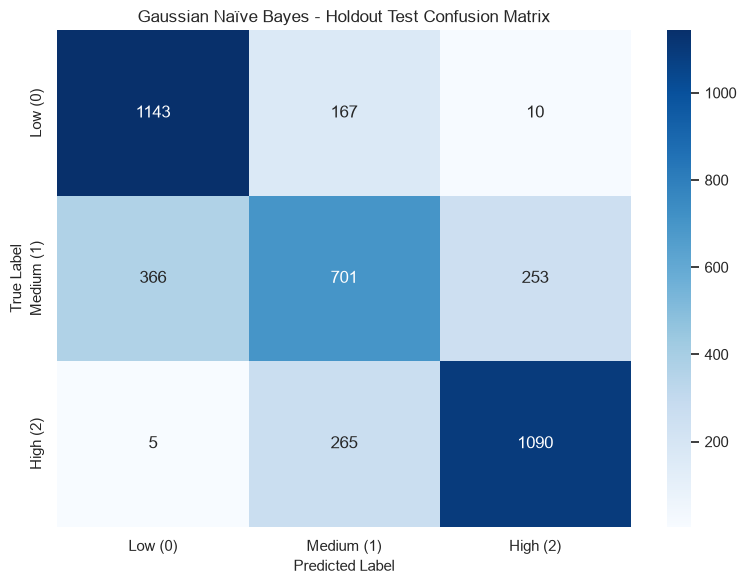

In [9]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
# Create a matplotlib figure to host the seaborn heatmap
plt.figure(figsize=(8, 6))

# Draw the heatmap, annotating cells with raw counts (fmt='d')
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)

# Add axis labels and title for academic clarity
plt.title("Gaussian Naïve Bayes - Holdout Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Use tight_layout to prevent clipping of labels during image export
plt.tight_layout()

# Display the figure inline
plt.show()

## 4. Learned Class-Conditional Feature Means

Gaussian Naïve Bayes stores, for every class, the mean of each predictor (in standardized units for the numeric features, and as the class-conditional proportion for the one-hot industry indicators). Comparing these means shows which features the model uses to distinguish the risk tiers.

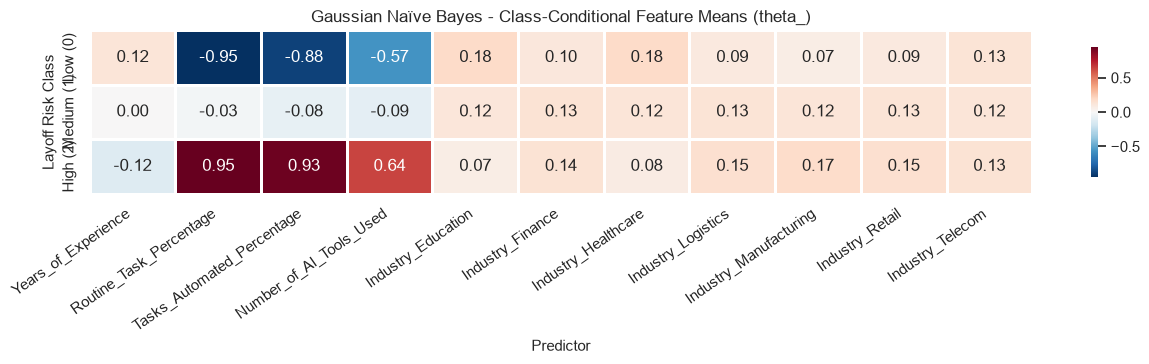

--- CLASS-CONDITIONAL MEANS TABLE ---


,Years_of_Experience,Routine_Task_Percentage,Tasks_Automated_Percentage,Number_of_AI_Tools_Used,Industry_Education,Industry_Finance,Industry_Healthcare,Industry_Logistics,Industry_Manufacturing,Industry_Retail,Industry_Telecom
Low (0),0.124,-0.951,-0.885,-0.572,0.181,0.104,0.180,0.094,0.074,0.091,0.129
Medium (1),0.004,-0.027,-0.077,-0.091,0.116,0.135,0.125,0.128,0.120,0.126,0.124
High (2),-0.124,0.950,0.935,0.643,0.072,0.137,0.079,0.150,0.175,0.151,0.135


In [10]:
# -------------------------------------------------------------------------
# Class-Conditional Feature Means (theta_)
# Rows = classes, columns = predictors. Numeric features are in z-score units.
# -------------------------------------------------------------------------
theta_df = pd.DataFrame(
    gnb.theta_,
    index=['Low (0)', 'Medium (1)', 'High (2)'],
    columns=X_train.columns
)

plt.figure(figsize=(13, 3.8))
sns.heatmap(theta_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.8, cbar_kws={"shrink": 0.8})
plt.title("Gaussian Naïve Bayes - Class-Conditional Feature Means (theta_)")
plt.xlabel("Predictor")
plt.ylabel("Layoff Risk Class")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

print("--- CLASS-CONDITIONAL MEANS TABLE ---")
display(theta_df.round(3))

> **Empirical Takeaway — How Naïve Bayes Separates the Tiers:**
> The class-conditional feature means ($	heta$) establish clear ordering across the three numeric automation predictors: standardized `Routine_Task_Percentage` averages **−0.950** for Low Risk, **−0.026** for Medium, and **+0.948** for High Risk; `Tasks_Automated_Percentage` follows an identical progression (**−0.883 / −0.077 / +0.933**), and `Number_of_AI_Tools_Used` ranges from **−0.572** (Low) to **+0.645** (High). Because the Medium risk distribution centers near zero across all standardized features, a symmetric Gaussian likelihood function produces substantial overlap with the tails of the Low and High distributions, directly explaining the lower sensitivity for Medium risk.